# Task 5: Stronger architectures and pre-trained models

**Objective:** increase validation accuracy (if possible) with
**(a)** more powerful architectures trained from scratch (ResNet, DenseNet), and
**(b)** pre-trained ImageNet models (VGG16, ResNet50) that are fine-tuned on this data.
Report accuracy *and* training/running time for each.

Adam Oakes

**Setup: the best pipeline from Tasks 3 and 4 is applied to every model**
* **Horizontal-flip augmentation** (Task 3's best) at the input and **Dropout(0.5) before the
  final Dense layer** (Task 4's best) are part of *every* model below, from scratch and pre-trained.
  So the only thing that changes between rows is the architecture and its starting weights.
* The baseline row, `task2_cnn`, is the Task 2 CNN with flip + Dropout(0.5): the Task 4 winner,
  retrained here so every model is compared on the same machine and in the same run.
* Images load at their native 32×32 and are cached in memory. Every model upsamples them to
  180×180 inside the network, the same way as in Task 2.
* Same seed and batch size (64) as before. From-scratch models train for up to 20 epochs; each
  pre-trained phase trains for up to 10. Early stopping ends a run after 3 epochs without a new best
  validation accuracy and restores the best epoch's weights.

**Part (a): stronger architectures from scratch** (random weights)
* `mini_resnet`: residual blocks with BatchNorm, in the same size class as the Task 2 CNN (about
  2.4M vs 1.6M parameters), so a change in accuracy mostly reflects the *design* (skip connections),
  not size. It is slower per epoch, though: every block runs two convolutions at full resolution.
* `mini_densenet`: dense blocks, where each layer receives every earlier layer's output.
* `resnet50_scratch`: the full ResNet50 (about 24M parameters) with **random** weights.

**Part (b): pre-trained ImageNet models**, in two phases
1. **Feature extraction:** freeze the whole pre-trained base and train only a new classifier head.
2. **Fine-tuning:** start from phase 1, unfreeze the *top* block of the base, and keep training
   at a 100× lower learning rate (1e-5), so the pre-trained features are adjusted, not wiped out.

`resnet50_scratch` and the two `resnet50_imagenet` rows use the identical architecture,
input preprocessing and head. The only difference is whether the starting weights are random
or come from ImageNet, so comparing them isolates the value of pre-training.

**Timing:** every row records seconds per epoch, total training time, and the time to run the
whole validation set through the model (inference). Fine-tuning rows also report the
*cumulative* time of both phases.

# Library imports and configuration

In [1]:
import os, json, time, platform
from pathlib import Path

import keras
from keras import layers
from keras.utils import image_dataset_from_directory
import tensorflow as tf
# Let TensorFlow take GPU memory as it needs it instead of grabbing it all up front
for _gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(_gpu, True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use("default")   # white background + dark text, regardless of the notebook theme

TASK = "task_5"

def find_project_root():
    # Walk up from the notebook's folder until we find the folder that holds data/train,
    # so the notebook works from code/, notebooks/code/ or anywhere else inside the project.
    here = Path.cwd().resolve()
    for d in [here, *here.parents]:
        if (d / "data" / "train").is_dir():
            return d
    raise FileNotFoundError("Couldn't find the project folder (one that contains data/train) "
                            f"above {here}. Set the DATA_DIR and OUT_DIR environment variables instead.")

ROOT = None if ("DATA_DIR" in os.environ and "OUT_DIR" in os.environ) else find_project_root()
DATA_DIR = Path(os.environ.get("DATA_DIR", ROOT / "data" if ROOT else ""))
EPOCHS = int(os.environ.get("EPOCHS", 20))         # from-scratch models (upper limit)
FE_EPOCHS = int(os.environ.get("FE_EPOCHS", 10))   # pre-trained, phase 1 (frozen base, upper limit)
FT_EPOCHS = int(os.environ.get("FT_EPOCHS", 10))   # pre-trained, phase 2 (fine-tuning, upper limit)
PATIENCE = 3                                       # same early-stopping rule as Tasks 3 and 4

# The best pipeline from Tasks 3 and 4, applied to every model
AUGMENTATION = [lambda: layers.RandomFlip("horizontal")]   # Task 3
HEAD_DROPOUT = 0.5                                         # Task 4
RUN_TAG = f"flip_drop{HEAD_DROPOUT:g}_e{EPOCHS}".replace(".", "")
FT_LR = 1e-5                                       # fine-tuning learning rate
BATCH_SIZE = 64
NATIVE_SIZE = (32, 32)
MODEL_SIZE = (180, 180)
SEED = 42
PRETRAINED_WEIGHTS = os.environ.get("PRETRAINED_WEIGHTS", "imagenet")  # "imagenet" for the real run

# Comment out any model you want to skip (for example, if a machine is too slow).
RUN = [
    "task2_cnn",
    "mini_resnet",
    "mini_densenet",
    "resnet50_scratch",
    "vgg16_imagenet",          # runs both phases: feature extraction, then fine-tuning
    "resnet50_imagenet",       # runs both phases: feature extraction, then fine-tuning
]

OUT = Path(os.environ.get("OUT_DIR", ROOT if ROOT else "."))
plots = OUT / "plots" / TASK
results_dir = OUT / "results" / TASK
ckpt_dir = OUT / "checkpoints" / TASK
for d in (plots, results_dir, ckpt_dir):
    d.mkdir(parents=True, exist_ok=True)
# File names include the pipeline and epoch limit, so results from an older setup are never
# mistaken for finished runs of this one.
RESULTS_CSV = results_dir / f"architectures_{RUN_TAG}.csv"
HISTORY_JSON = results_dir / f"architectures_{RUN_TAG}_histories.json"

GPUS = tf.config.list_physical_devices("GPU")
MACHINE = f"{platform.node()} | {platform.machine()} | GPUs: {len(GPUS)}"
print(MACHINE)
print("results ->", RESULTS_CSV.resolve())

Raizen | x86_64 | GPUs: 1
results -> /home/adam/projects/Real_vs_Fake_Classifier/results/task_5/architectures_flip_drop05_e20.csv


**About timing across computers:** training times only mean something when they're measured on
the same machine. Each row records which machine it ran on (the `machine` column). Compare times
*within* this table, and don't compare them with Tasks 2–4 if those ran on a different computer.

# Load the data (native 32×32, cached in memory)

In [2]:
def load(split, shuffle):
    return image_dataset_from_directory(
        DATA_DIR / split, image_size=NATIVE_SIZE, batch_size=BATCH_SIZE,
        shuffle=shuffle, seed=SEED,
    )

train_dataset = load("train", shuffle=True)
validation_dataset = load("validation", shuffle=False)
print(train_dataset.class_names)

train_ds = (train_dataset.unbatch().cache()
            .shuffle(20_000, seed=SEED, reshuffle_each_iteration=True)
            .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
val_ds = validation_dataset.cache().prefetch(tf.data.AUTOTUNE)

Found 80000 files belonging to 2 classes.
Found 20000 files belonging to 2 classes.
['FAKE', 'REAL']


# Part (a): architectures trained from scratch

In [3]:
def upsampled_input():
    inputs = keras.Input(shape=NATIVE_SIZE + (3,))
    x = inputs
    for make in AUGMENTATION:                 # horizontal flip (Task 3); active only during training
        x = make()(x)
    x = layers.Resizing(*MODEL_SIZE, interpolation="bilinear")(x)   # same 32->180 upsample as Task 2
    return inputs, x

def classifier_head(x):
    # Dropout(0.5) before the final Dense layer (Task 4), shared by every model
    x = layers.Dropout(HEAD_DROPOUT)(x)
    return layers.Dense(1, activation="sigmoid")(x)

def task2_cnn():
    # The Task 2 CNN with the Task 3/4 pipeline: the baseline row
    inputs, x = upsampled_input()
    x = layers.Rescaling(1.0 / 255)(x)
    for f in [32, 64, 128, 256]:
        x = layers.Conv2D(f, 3, activation="relu")(x)
        x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(512, 3, activation="relu")(x)
    x = layers.GlobalAveragePooling2D()(x)
    outputs = classifier_head(x)
    return keras.Model(inputs, outputs, name="task2_cnn")

def residual_block(x, filters, pooling):
    # Two 3x3 convs, plus a shortcut that skips over them. The block only has to learn a
    # *correction* to its input; this keeps gradients flowing through deep stacks.
    shortcut = x
    for _ in range(2):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
    if pooling:
        x = layers.MaxPooling2D(2, padding="same")(x)
        shortcut = layers.Conv2D(filters, 1, strides=2)(shortcut)   # match the new shape
    elif shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(filters, 1)(shortcut)
    return layers.add([x, shortcut])

def mini_resnet():
    inputs, x = upsampled_input()
    x = layers.Rescaling(1.0 / 255)(x)
    x = layers.Conv2D(32, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    for f in [32, 64, 128, 256]:
        x = residual_block(x, f, pooling=True)
    x = residual_block(x, 256, pooling=False)
    x = layers.GlobalAveragePooling2D()(x)
    outputs = classifier_head(x)
    return keras.Model(inputs, outputs, name="mini_resnet")

def dense_block(x, n_layers, growth):
    # Each layer sees the concatenation of ALL previous layers' outputs (feature reuse),
    # and adds `growth` new channels to the stack.
    for _ in range(n_layers):
        y = layers.BatchNormalization()(x)
        y = layers.Activation("relu")(y)
        y = layers.Conv2D(4 * growth, 1, use_bias=False)(y)      # bottleneck
        y = layers.BatchNormalization()(y)
        y = layers.Activation("relu")(y)
        y = layers.Conv2D(growth, 3, padding="same", use_bias=False)(y)
        x = layers.Concatenate()([x, y])
    return x

def transition(x):
    # Halve the channels (compression) and the spatial size between dense blocks
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(x.shape[-1] // 2, 1, use_bias=False)(x)
    return layers.AveragePooling2D(2)(x)

def mini_densenet(growth=24, blocks=(4, 6, 8, 6)):
    inputs, x = upsampled_input()
    x = layers.Rescaling(1.0 / 255)(x)
    x = layers.Conv2D(2 * growth, 3, strides=2, padding="same", use_bias=False)(x)   # 180 -> 90
    x = layers.MaxPooling2D(2)(x)                                                    # 90 -> 45
    for i, n in enumerate(blocks):
        x = dense_block(x, n, growth)
        if i < len(blocks) - 1:
            x = transition(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.GlobalAveragePooling2D()(x)
    outputs = classifier_head(x)
    return keras.Model(inputs, outputs, name="mini_densenet")

# Part (b): pre-trained base + new head

Both VGG16 and ResNet50 were trained on ImageNet with "caffe" preprocessing (RGB→BGR plus
mean subtraction). The images must be fed the same way, or the pre-trained filters see inputs
they were never trained on. `resnet50_scratch` uses the same preprocessing, so the scratch vs
pre-trained comparison changes *only* the starting weights.

The base is always called with `training=False`. For ResNet50 this keeps its BatchNorm layers
using their ImageNet statistics, even after unfreezing. Otherwise the first fine-tuning batches
would overwrite those statistics and wreck the pre-trained features.

In [4]:
BASES = {
    # name: (constructor, preprocess fn, name prefix of the top block to unfreeze when fine-tuning)
    "vgg16":    (keras.applications.VGG16,    keras.applications.vgg16.preprocess_input,    "block5_"),
    "resnet50": (keras.applications.ResNet50, keras.applications.resnet50.preprocess_input, "conv5_"),
}

def pretrained_model(base_name, weights):
    make, preprocess, _ = BASES[base_name]
    base = make(weights=weights, include_top=False, input_shape=MODEL_SIZE + (3,))
    inputs, x = upsampled_input()
    x = layers.Lambda(preprocess, name="preprocess")(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    outputs = classifier_head(x)
    model = keras.Model(inputs, outputs, name=f"{base_name}_{weights or 'scratch'}")
    return model, base

def set_trainable(base, mode, top_prefix=None):
    # mode: "all" | "none" | "top" (only layers whose name starts with top_prefix)
    base.trainable = mode != "none"
    if mode == "top":
        for layer in base.layers:
            layer.trainable = layer.name.startswith(top_prefix)

def count_trainable(model):
    return int(sum(np.prod(w.shape) for w in model.trainable_weights))

# Training loop

Every configuration is timed. Results go to a CSV **after each row**, and the phase-1 weights
of the pre-trained models are saved to `checkpoints/task_5/`. If the kernel dies, re-running
the cell skips finished rows, and fine-tuning resumes from the saved phase-1 weights.

In [5]:
class EpochTimer(keras.callbacks.Callback):
    def on_train_begin(self, logs=None): self.times = []
    def on_epoch_begin(self, epoch, logs=None): self.t0 = time.time()
    def on_epoch_end(self, epoch, logs=None): self.times.append(time.time() - self.t0)

def load_results():
    return pd.read_csv(RESULTS_CSV) if RESULTS_CSV.exists() else pd.DataFrame()

def is_done(name):
    r = load_results()
    return len(r) and name in set(r["config"])

def fit_and_record(model, name, part, method, epochs, lr, prior_sec=0.0, prior_epochs=0):
    model.compile(loss="binary_crossentropy", metrics=["accuracy"],
                  optimizer=keras.optimizers.Adam(learning_rate=lr))
    timer = EpochTimer()
    cb = [timer, keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=PATIENCE,
                                               mode="max", restore_best_weights=True)]
    t0 = time.time()
    h = model.fit(train_ds, epochs=epochs, validation_data=val_ds, callbacks=cb, verbose=2)
    train_sec = time.time() - t0
    t1 = time.time()
    model.evaluate(val_ds, verbose=0)                 # inference time over the 20k validation images
    infer_sec = time.time() - t1

    hist = {k: [float(v) for v in vals] for k, vals in h.history.items()}
    best = int(np.argmax(hist["val_accuracy"]))
    n_ep = len(hist["accuracy"])
    row = dict(
        config=name, part=part, method=method, machine=MACHINE,
        total_params=model.count_params(), trainable_params=count_trainable(model),
        best_val_acc=hist["val_accuracy"][best], best_epoch=best + 1,
        final_train_acc=hist["accuracy"][-1], final_val_acc=hist["val_accuracy"][-1],
        epochs_run=n_ep, sec_per_epoch=float(np.median(timer.times)),
        first_epoch_sec=timer.times[0], train_sec=train_sec,
        cumulative_epochs=prior_epochs + n_ep, cumulative_train_sec=prior_sec + train_sec,
        val_inference_sec=infer_sec,
    )
    pd.concat([load_results(), pd.DataFrame([row])], ignore_index=True).to_csv(RESULTS_CSV, index=False)
    hs = json.loads(HISTORY_JSON.read_text()) if HISTORY_JSON.exists() else {}
    hs[name] = hist
    HISTORY_JSON.write_text(json.dumps(hs))
    print(f"==> {name}: best val_acc {row['best_val_acc']:.4f} | "
          f"{row['sec_per_epoch']:.0f} s/epoch | {train_sec/60:.1f} min total")
    return row

SCRATCH = {"task2_cnn": task2_cnn, "mini_resnet": mini_resnet, "mini_densenet": mini_densenet}

import gc
for name in RUN:
    keras.backend.clear_session()   # free the previous model's memory before building the next one
    gc.collect()
    if name in SCRATCH:
        if is_done(name): print(f"skip {name}"); continue
        keras.utils.set_random_seed(SEED)
        method = "baseline (Task 2 CNN + flip + dropout)" if name == "task2_cnn" else "from scratch"
        fit_and_record(SCRATCH[name](), name, "a", method, EPOCHS, 1e-3)

    elif name == "resnet50_scratch":
        if is_done(name): print(f"skip {name}"); continue
        keras.utils.set_random_seed(SEED)
        model, base = pretrained_model("resnet50", None)
        set_trainable(base, "all")
        fit_and_record(model, name, "a", "from scratch (random weights)", EPOCHS, 1e-3)

    elif name.endswith("_imagenet"):
        base_name = name.split("_")[0]
        fe_name, ft_name = f"{name}_feature_extract", f"{name}_fine_tune"
        fe_weights = ckpt_dir / f"{fe_name}_{RUN_TAG}.weights.h5"

        keras.utils.set_random_seed(SEED)
        model, base = pretrained_model(base_name, PRETRAINED_WEIGHTS)

        # Phase 1: frozen base, train only the head
        if not is_done(fe_name):
            set_trainable(base, "none")
            fit_and_record(model, fe_name, "b", "pre-trained, frozen base (feature extraction)",
                           FE_EPOCHS, 1e-3)
            model.save_weights(fe_weights)
        else:
            print(f"skip {fe_name}")

        # Phase 2: unfreeze the top block, low learning rate
        if not is_done(ft_name):
            set_trainable(base, "none")                # match phase-1 layout, then load its weights
            model.load_weights(fe_weights)
            set_trainable(base, "top", BASES[base_name][2])
            prev = load_results().set_index("config").loc[fe_name]
            fit_and_record(model, ft_name, "b",
                           f"pre-trained, fine-tune top block ({BASES[base_name][2]}*), lr={FT_LR:g}",
                           FT_EPOCHS, FT_LR,
                           prior_sec=float(prev.train_sec), prior_epochs=int(prev.epochs_run))
        else:
            print(f"skip {ft_name}")

Epoch 1/20


/home/adam/.virtualenvs/dl/lib/python3.10/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


1250/1250 - 54s - 43ms/step - accuracy: 0.8003 - loss: 0.4323 - val_accuracy: 0.8325 - val_loss: 0.3831
Epoch 2/20
1250/1250 - 36s - 29ms/step - accuracy: 0.8873 - loss: 0.2738 - val_accuracy: 0.8971 - val_loss: 0.2532
Epoch 3/20
1250/1250 - 36s - 29ms/step - accuracy: 0.9070 - loss: 0.2297 - val_accuracy: 0.9129 - val_loss: 0.2141
Epoch 4/20
1250/1250 - 36s - 29ms/step - accuracy: 0.9189 - loss: 0.2049 - val_accuracy: 0.9214 - val_loss: 0.1933
Epoch 5/20
1250/1250 - 36s - 29ms/step - accuracy: 0.9259 - loss: 0.1887 - val_accuracy: 0.9236 - val_loss: 0.1879
Epoch 6/20
1250/1250 - 37s - 29ms/step - accuracy: 0.9307 - loss: 0.1767 - val_accuracy: 0.9342 - val_loss: 0.1682
Epoch 7/20
1250/1250 - 36s - 29ms/step - accuracy: 0.9324 - loss: 0.1708 - val_accuracy: 0.9204 - val_loss: 0.2008
Epoch 8/20
1250/1250 - 36s - 28ms/step - accuracy: 0.9373 - loss: 0.1595 - val_accuracy: 0.9411 - val_loss: 0.1583
Epoch 9/20
1250/1250 - 36s - 29ms/step - accuracy: 0.9402 - loss: 0.1537 - val_accuracy: 0.

/home/adam/.virtualenvs/dl/lib/python3.10/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


1250/1250 - 167s - 134ms/step - accuracy: 0.8774 - loss: 0.2985 - val_accuracy: 0.8975 - val_loss: 0.2697
Epoch 2/20
1250/1250 - 136s - 108ms/step - accuracy: 0.9246 - loss: 0.1931 - val_accuracy: 0.9130 - val_loss: 0.2288
Epoch 3/20
1250/1250 - 135s - 108ms/step - accuracy: 0.9352 - loss: 0.1694 - val_accuracy: 0.8131 - val_loss: 0.6570
Epoch 4/20
1250/1250 - 136s - 109ms/step - accuracy: 0.9390 - loss: 0.1577 - val_accuracy: 0.9378 - val_loss: 0.1654
Epoch 5/20
1250/1250 - 135s - 108ms/step - accuracy: 0.9453 - loss: 0.1428 - val_accuracy: 0.8676 - val_loss: 0.4384
Epoch 6/20
1250/1250 - 135s - 108ms/step - accuracy: 0.9488 - loss: 0.1355 - val_accuracy: 0.9233 - val_loss: 0.1947
Epoch 7/20
1250/1250 - 135s - 108ms/step - accuracy: 0.9519 - loss: 0.1278 - val_accuracy: 0.9369 - val_loss: 0.1722
==> mini_resnet: best val_acc 0.9378 | 135 s/epoch | 16.3 min total
Epoch 1/20


/home/adam/.virtualenvs/dl/lib/python3.10/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


... (7 outputs left out)

/home/adam/.virtualenvs/dl/lib/python3.10/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


1250/1250 - 54s - 43ms/step - accuracy: 0.8535 - loss: 0.3335 - val_accuracy: 0.9194 - val_loss: 0.2091
Epoch 2/10
1250/1250 - 42s - 34ms/step - accuracy: 0.8827 - loss: 0.2800 - val_accuracy: 0.9198 - val_loss: 0.2017
Epoch 3/10
1250/1250 - 42s - 34ms/step - accuracy: 0.8833 - loss: 0.2782 - val_accuracy: 0.9190 - val_loss: 0.2033
Epoch 4/10
1250/1250 - 41s - 33ms/step - accuracy: 0.8834 - loss: 0.2801 - val_accuracy: 0.9260 - val_loss: 0.1928
Epoch 5/10
1250/1250 - 42s - 34ms/step - accuracy: 0.8834 - loss: 0.2801 - val_accuracy: 0.9229 - val_loss: 0.1954
Epoch 6/10
1250/1250 - 42s - 33ms/step - accuracy: 0.8831 - loss: 0.2806 - val_accuracy: 0.9244 - val_loss: 0.1928
Epoch 7/10
1250/1250 - 41s - 33ms/step - accuracy: 0.8855 - loss: 0.2782 - val_accuracy: 0.9238 - val_loss: 0.1941
==> resnet50_imagenet_feature_extract: best val_acc 0.9260 | 42 s/epoch | 5.1 min total
Epoch 1/10


/home/adam/.virtualenvs/dl/lib/python3.10/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


1250/1250 - 69s - 55ms/step - accuracy: 0.9204 - loss: 0.2109 - val_accuracy: 0.9582 - val_loss: 0.1100
Epoch 2/10
1250/1250 - 51s - 41ms/step - accuracy: 0.9585 - loss: 0.1093 - val_accuracy: 0.9701 - val_loss: 0.0814
Epoch 3/10
1250/1250 - 51s - 41ms/step - accuracy: 0.9729 - loss: 0.0716 - val_accuracy: 0.9733 - val_loss: 0.0743
Epoch 4/10
1250/1250 - 51s - 41ms/step - accuracy: 0.9829 - loss: 0.0470 - val_accuracy: 0.9744 - val_loss: 0.0775
Epoch 5/10
1250/1250 - 51s - 41ms/step - accuracy: 0.9878 - loss: 0.0327 - val_accuracy: 0.9761 - val_loss: 0.0737
Epoch 6/10
1250/1250 - 52s - 41ms/step - accuracy: 0.9919 - loss: 0.0230 - val_accuracy: 0.9768 - val_loss: 0.0788
Epoch 7/10
1250/1250 - 51s - 41ms/step - accuracy: 0.9946 - loss: 0.0151 - val_accuracy: 0.9767 - val_loss: 0.0806
Epoch 8/10
1250/1250 - 52s - 41ms/step - accuracy: 0.9965 - loss: 0.0111 - val_accuracy: 0.9764 - val_loss: 0.0860
Epoch 9/10
1250/1250 - 51s - 41ms/step - accuracy: 0.9966 - loss: 0.0097 - val_accuracy: 0.

# Results table

In [6]:
res = load_results()
base_acc = res.loc[res.config == "task2_cnn", "best_val_acc"].item() if "task2_cnn" in set(res.config) else np.nan
res["delta_vs_baseline"] = res.best_val_acc - base_acc
cols = ["part", "config", "method", "total_params", "trainable_params", "best_val_acc",
        "delta_vs_baseline", "cumulative_epochs", "sec_per_epoch", "cumulative_train_sec", "val_inference_sec"]
table = res[cols].copy()

def to_markdown(df):
    fmt = {"total_params": "{:,}", "trainable_params": "{:,}", "best_val_acc": "{:.4f}",
           "delta_vs_baseline": "{:+.4f}", "sec_per_epoch": "{:.0f}",
           "cumulative_train_sec": "{:.0f}", "val_inference_sec": "{:.1f}"}
    lines = ["| " + " | ".join(df.columns) + " |", "|" + "---|" * len(df.columns)]
    for _, r in df.iterrows():
        lines.append("| " + " | ".join(fmt.get(c, "{}").format(r[c]) for c in df.columns) + " |")
    return "\n".join(lines)

md_table = to_markdown(table)
(results_dir / f"architectures_{RUN_TAG}.md").write_text(md_table)
from IPython.display import Markdown, display
display(Markdown(md_table))
print("Measured on:", res.machine.unique())

| part | config | method | total_params | trainable_params | best_val_acc | delta_vs_baseline | cumulative_epochs | sec_per_epoch | cumulative_train_sec | val_inference_sec |
|---|---|---|---|---|---|---|---|---|---|---|
| a | task2_cnn | baseline (Task 2 CNN + flip + dropout) | 1,569,089 | 1,569,089 | 0.9492 | +0.0000 | 20 | 36 | 735 | 2.0 |
| a | mini_resnet | from scratch | 2,410,945 | 2,407,937 | 0.9378 | -0.0114 | 7 | 135 | 979 | 7.7 |
| a | mini_densenet | from scratch | 983,383 | 969,019 | 0.9596 | +0.0104 | 12 | 46 | 615 | 2.8 |
| a | resnet50_scratch | from scratch (random weights) | 23,589,761 | 23,536,641 | 0.9613 | +0.0121 | 14 | 210 | 3000 | 8.4 |
| b | vgg16_imagenet_feature_extract | pre-trained, frozen base (feature extraction) | 14,715,201 | 513 | 0.8635 | -0.0857 | 7 | 87 | 628 | 17.3 |
| b | vgg16_imagenet_fine_tune | pre-trained, fine-tune top block (block5_*), lr=1e-05 | 14,715,201 | 7,079,937 | 0.9729 | +0.0236 | 17 | 94 | 1574 | 16.7 |
| b | resnet50_imagenet_feature_extract | pre-trained, frozen base (feature extraction) | 23,589,761 | 2,049 | 0.9260 | -0.0232 | 7 | 42 | 305 | 8.6 |
| b | resnet50_imagenet_fine_tune | pre-trained, fine-tune top block (conv5_*), lr=1e-05 | 23,589,761 | 14,978,049 | 0.9778 | +0.0285 | 17 | 51 | 835 | 8.6 |

Measured on: ['Raizen | x86_64 | GPUs: 1']


# Plots

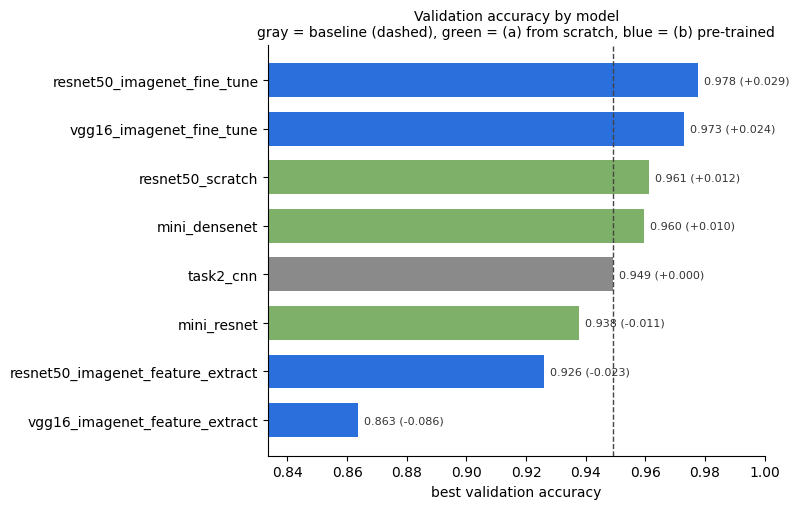

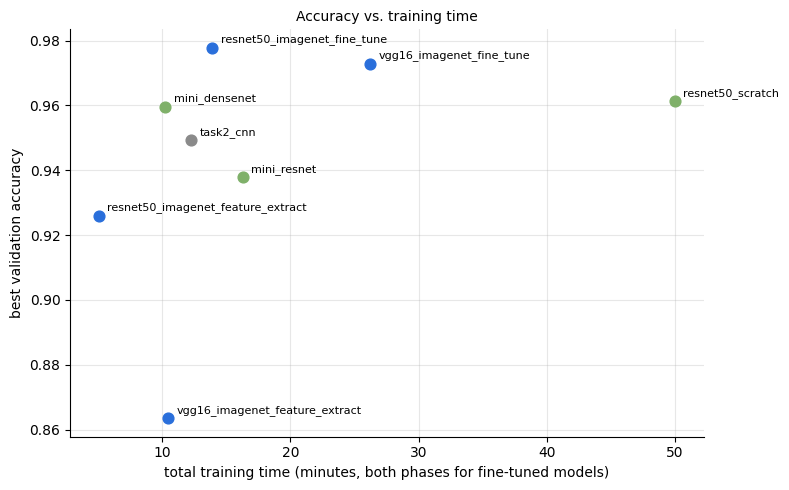

In [7]:
# 1) Validation accuracy per model
t = res.sort_values("best_val_acc")
colors = ["#8a8a8a" if c == "task2_cnn" else ("#2a6fdb" if p == "b" else "#7fb069")
          for c, p in zip(t.config, t.part)]
fig, ax = plt.subplots(figsize=(8, 0.5 * len(t) + 1.2))
ax.barh(t.config, t.best_val_acc, color=colors, height=0.7)
if not np.isnan(base_acc):
    ax.axvline(base_acc, color="#444", lw=1, ls="--")
for y, (v, d) in enumerate(zip(t.best_val_acc, t.delta_vs_baseline)):
    ax.text(v + 0.002, y, f"{v:.3f} ({d:+.3f})", va="center", fontsize=8, color="#333")
ax.set_xlim(max(0.5, t.best_val_acc.min() - 0.03), min(1.0, t.best_val_acc.max() + 0.05))
ax.set_xlabel("best validation accuracy")
ax.set_title("Validation accuracy by model\n"
             "gray = baseline (dashed), green = (a) from scratch, blue = (b) pre-trained", fontsize=10)
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout(); fig.savefig(plots / "val_acc_by_model.png", dpi=150); plt.show()

# 2) Accuracy vs. cost: is the extra training time buying anything?
fig, ax = plt.subplots(figsize=(8, 5))
for _, r in res.iterrows():
    c = "#8a8a8a" if r.config == "task2_cnn" else ("#2a6fdb" if r.part == "b" else "#7fb069")
    ax.scatter(r.cumulative_train_sec / 60, r.best_val_acc, s=60, color=c, zorder=3)
    ax.annotate(r.config, (r.cumulative_train_sec / 60, r.best_val_acc),
                textcoords="offset points", xytext=(6, 4), fontsize=8)
ax.set_xlabel("total training time (minutes, both phases for fine-tuned models)")
ax.set_ylabel("best validation accuracy")
ax.set_title("Accuracy vs. training time", fontsize=10)
ax.grid(alpha=0.3)
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout(); fig.savefig(plots / "acc_vs_time.png", dpi=150); plt.show()

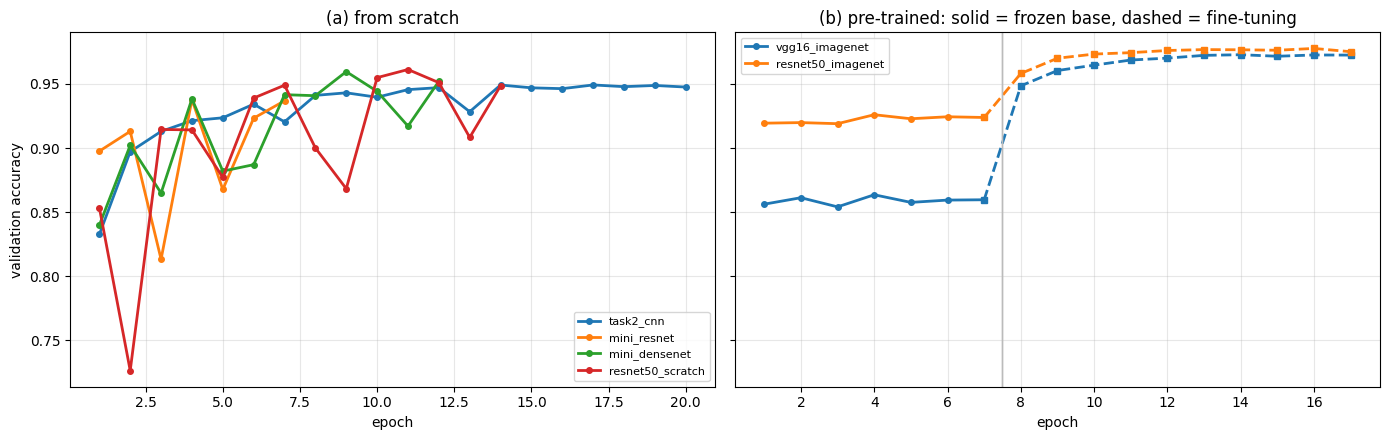

In [8]:
# 3) Learning curves (validation accuracy per epoch). Fine-tuning continues the feature-extraction curve.
hs = json.loads(HISTORY_JSON.read_text())
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for name in [c for c in res.config if res.set_index("config").loc[c, "part"] == "a"]:
    v = hs[name]["val_accuracy"]
    axes[0].plot(range(1, len(v) + 1), v, marker="o", ms=4, lw=2, label=name)
axes[0].set_title("(a) from scratch"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("validation accuracy")
for name in [c for c in res.config if c.endswith("_feature_extract")]:
    fe = hs[name]["val_accuracy"]
    ft = hs.get(name.replace("_feature_extract", "_fine_tune"), {}).get("val_accuracy", [])
    line, = axes[1].plot(range(1, len(fe) + 1), fe, marker="o", ms=4, lw=2,
                         label=name.replace("_feature_extract", ""))
    if ft:
        axes[1].plot(range(len(fe), len(fe) + len(ft) + 1), [fe[-1]] + ft, marker="s", ms=4, lw=2,
                     ls="--", color=line.get_color())
        axes[1].axvline(len(fe) + 0.5, color="#bbb", lw=1)
axes[1].set_title("(b) pre-trained: solid = frozen base, dashed = fine-tuning")
axes[1].set_xlabel("epoch")
for ax in axes: ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); fig.savefig(plots / "learning_curves.png", dpi=150); plt.show()

# Discussion

Every model uses the best pipeline from Tasks 3 and 4 (horizontal flip + Dropout(0.5) before the final
layer). The baseline, the Task 2 CNN, reached **0.9492** in 12 minutes of training.

**(a) Stronger architectures from scratch** gave modest gains at best: ResNet50 reached 0.9613 (+1.2) but
took 50 minutes, and the mini DenseNet reached 0.9596 (+1.0) with fewer parameters and less training time
than the baseline. The mini ResNet scored 0.9378 (−1.1). All three use BatchNorm, and their validation
accuracy swung widely from epoch to epoch, so early stopping ended some runs early, the mini ResNet's after
only 7 epochs.

**(b) Pre-trained models** gave the best results, but only after fine-tuning. With the base frozen, VGG16
reached only 0.8635 and ResNet50 0.9260: ImageNet's deep features are built to separate objects, while real
and fake images contain the same kinds of objects. Fine-tuning the top block raised them to **0.9729
(VGG16)** and **0.9778 (ResNet50, the best overall, +2.9)**. Pre-trained ResNet50 also beat the same
architecture trained from scratch by 1.7 points, in 14 minutes instead of 50.

**Timing:** fine-tuned ResNet50 is the best accuracy-for-time trade-off. VGG16 took about twice as long to
train and is about twice as slow at inference, for slightly lower accuracy.

**Caveats:** one seed per model; differences of about one point among the from-scratch models are only about
twice the run-to-run noise measured in Task 4.

# Acknowledgment of AI assistance

This notebook was developed with help from Claude (Opus 5.5), an AI assistant made by Anthropic.

**Claude contributed:** the design of the experiment (applying the Task 3/4 pipeline to every model, the
two-phase pre-trained setup, and the matched ResNet50 scratch vs. pre-trained comparison); the notebook code,
including the mini ResNet and mini DenseNet and the timing measurements; a small test run on a sample of the
data to check that the code worked; and a first draft of the Discussion, written from the results of my run.

**My contributions:** running the full experiment on my machine, reviewing the results and editing
the analysis.

**Citation:** Anthropic. (2026). *Claude* (Opus 5.5) [Large language model]. https://claude.ai.
Accessed November 16, 2026.